## TUGAS PEMROGRAMAN PARALEL 4 (Pertemuan 7)

#### Nama           : Naila Faiza Inshyra
#### NIM            : 2411512013
#### Kelas          : Pemrograman Paralel A
#### Jurusan        : Teknik Komputer
#### Dosen Pengampu : Ibu Desta Yolanda

### Tahap Awal: Import, Fungsi Pengambil Data PyPI, dan File Helper

Sel ini menyiapkan semua yang dipakai bersama oleh beberapa soal:

- **Daftar 30 paket PyPI** populer (soal 1). Enam nama pertama sama dengan modul; sisanya saya tambah sendiri.
- `ambil_metadata_paket()` memanggil REST API sungguhan `https://pypi.org/pypi/<paket>/json` (bukan simulasi), sama dengan bagian 6.1 modul. Saya menambahkan `try/except` agar satu kegagalan jaringan tidak menggagalkan seluruh eksperimen; kegagalan dihitung dan dilaporkan.
- `tugas4_helpers.py` ditulis ke disk hanya untuk **soal 4** (benchmark `multiprocessing`). Alasannya sama seperti Tugas 3: fungsi untuk proses anak harus bisa di-*pickle*, jadi tidak boleh didefinisikan di dalam sel notebook (khususnya pada Windows yang memakai `spawn`).

In [1]:
%%writefile tugas4_helpers.py
import time

def tugas_io(durasi):
    """Simulasi 1 tugas I/O-bound: hanya menunggu (seperti menunggu respons jaringan)."""
    time.sleep(durasi)
    return durasi

Overwriting tugas4_helpers.py


In [2]:
import asyncio, time, statistics, math, itertools, random, logging
import aiohttp
import numpy as np
import matplotlib.pyplot as plt

# 30 nama paket PyPI populer (6 pertama = daftar di modul)
daftar_paket_banyak = [
    "requests", "numpy", "flask", "aiohttp", "pandas", "django",
    "scipy", "matplotlib", "pillow", "sqlalchemy", "pytest", "boto3",
    "urllib3", "setuptools", "certifi", "idna", "packaging", "pyyaml",
    "jinja2", "click", "cryptography", "fastapi", "uvicorn", "beautifulsoup4",
    "lxml", "scikit-learn", "pydantic", "attrs", "rich", "httpx",
]
print(f"Jumlah paket: {len(daftar_paket_banyak)}  (unik: {len(set(daftar_paket_banyak))})")

async def ambil_metadata_paket(session, nama_paket):
    url = f"https://pypi.org/pypi/{nama_paket}/json"
    try:
        async with session.get(url) as response:
            response.raise_for_status()
            data = await response.json()
        info = data["info"]
        return {"nama": info["name"], "versi": info["version"],
                "summary": (info["summary"] or "")[:60]}
    except Exception as e:                       # jaringan putus, 404, timeout, dst.
        return {"nama": nama_paket, "error": repr(e)}

async def ambil_dengan_batas(session, nama_paket, semaphore):
    async with semaphore:                        # hanya N coroutine yang boleh masuk bersamaan
        return await ambil_metadata_paket(session, nama_paket)

async def jalankan_dengan_batas(batas, paket=daftar_paket_banyak):
    """Ambil semua paket dengan maksimal `batas` request bersamaan.
    Session baru tiap pemanggilan -> koneksi (TCP+TLS) dibuat ulang, jadi tiap run adil."""
    semaphore = asyncio.Semaphore(batas)
    timeout = aiohttp.ClientTimeout(total=30)
    start = time.perf_counter()
    async with aiohttp.ClientSession(timeout=timeout) as session:
        hasil = await asyncio.gather(*[ambil_dengan_batas(session, p, semaphore) for p in paket])
    waktu = time.perf_counter() - start
    gagal = [h for h in hasil if "error" in h]
    return waktu, hasil, gagal

Jumlah paket: 30  (unik: 30)


### SOAL NOMOR 1

Soal Nomor 1:
Eksperimen Skala: Perbesar daftar_paket_banyak menjadi 20–30 nama paket PyPI valid (cari sendiri nama-nama package populer). Bandingkan waktu total untuk BATAS_KONKURENSI = 1, 3, 5, 10, 20. Plot waktu vs batas konkurensi. Pada titik berapa penambahan batas konkurensi mulai memberi manfaat yang sangat kecil? Kaitkan dengan konsep *diminishing returns* dari Hukum Amdahl (Pertemuan 1).

**Rancangan eksperimen**

- **Beban:** 30 paket PyPI (di atas batas 20–30 yang diminta), request jaringan sungguhan.
- **Variabel bebas:** `BATAS_KONKURENSI` ∈ {1, 3, 5, 10, 20}, diterapkan dengan `asyncio.Semaphore`.
- **Validasi dulu:** semua 30 nama diambil sekali; jika ada yang gagal/tidak valid, langsung terlihat.
- **Warm-up:** satu run pemanasan dibuang (cache DNS/CDN), supaya konfigurasi yang kebetulan dijalankan pertama tidak dirugikan.
- **Pengulangan:** tiap konfigurasi diulang 5 kali dan diambil **median** (jaringan sifatnya berfluktuasi). Urutan dibuat *round-robin* (ulangan 1 untuk semua batas, lalu ulangan 2, dst.) agar perubahan kondisi jaringan selama eksperimen tidak menimpa satu konfigurasi saja.
- **Speedup:** $S(N) = T(1) / T(N)$.
- **Pembanding teoritis:**
  - *Model gelombang*: 30 tugas dengan batas $N$ diselesaikan dalam $\lceil 30/N \rceil$ gelombang, sehingga waktu ideal $\approx \lceil 30/N \rceil \times t_{\text{request}}$.
  - *Hukum Amdahl*: $S(N) = \dfrac{1}{(1-P) + P/N}$, dengan $P$ diestimasi dari data.

In [3]:
# --- Langkah 0: validasi 30 nama paket (sekali jalan) ---
waktu_val, hasil_val, gagal_val = await jalankan_dengan_batas(10)
print(f"Validasi selesai dalam {waktu_val:.2f} detik; berhasil {len(hasil_val)-len(gagal_val)}/{len(hasil_val)} paket\n")
for h in hasil_val:
    if "error" in h:
        print(f"  [GAGAL] {h['nama']:<18} {h['error']}")
    else:
        print(f"  [OK]    {h['nama']:<18} v{h['versi']:<12} {h['summary']}")
assert not gagal_val, "Ada nama paket tidak valid / request gagal -> perbaiki daftar_paket_banyak"

Validasi selesai dalam 0.60 detik; berhasil 30/30 paket

  [OK]    requests           v2.34.2       Python HTTP for Humans.
  [OK]    numpy              v2.5.4        Fundamental package for array computing in Python
  [OK]    Flask              v3.1.3        A simple framework for building complex web applications.
  [OK]    aiohttp            v3.14.5       Async http client/server framework (asyncio)
  [OK]    pandas             v3.0.6        Powerful data structures for data analysis, time series, and
  [OK]    Django             v6.1.2        A high-level Python web framework that encourages rapid deve
  [OK]    scipy              v1.18.1       Fundamental algorithms for scientific computing in Python
  [OK]    matplotlib         v3.11.2       Python plotting package
  [OK]    pillow             v12.3.0       Python Imaging Library (fork)
  [OK]    SQLAlchemy         v2.1.4        Database Abstraction Library
  [OK]    pytest             v9.1.1        pytest: simple powerful testin

In [4]:
BATAS_LIST = [1, 3, 5, 10, 20]
ULANG = 5

# --- Warm-up (dibuang) ---
await jalankan_dengan_batas(10)

# --- Eksperimen: round-robin antar konfigurasi ---
mentah = {b: [] for b in BATAS_LIST}
total_gagal = 0
for rep in range(ULANG):
    for b in BATAS_LIST:
        waktu, hasil, gagal = await jalankan_dengan_batas(b)
        mentah[b].append(waktu)
        total_gagal += len(gagal)
    print(f"ulangan {rep+1}/{ULANG} selesai")

waktu_med = {b: statistics.median(mentah[b]) for b in BATAS_LIST}

print(f"\nRequest gagal selama eksperimen: {total_gagal}  (harus 0 agar perbandingan valid)\n")
print(f"{'BATAS':>5} | {'ulangan (detik)':<38} | {'median':>7}")
for b in BATAS_LIST:
    runs = ", ".join(f"{t:.3f}" for t in mentah[b])
    print(f"{b:>5} | {runs:<38} | {waktu_med[b]:>6.3f}s")

ulangan 1/5 selesai


ulangan 2/5 selesai


ulangan 3/5 selesai


ulangan 4/5 selesai


ulangan 5/5 selesai

Request gagal selama eksperimen: 0  (harus 0 agar perbandingan valid)

BATAS | ulangan (detik)                        |  median
    1 | 1.162, 5.322, 2.298, 2.124, 1.572      |  2.124s
    3 | 0.799, 0.744, 0.669, 0.610, 0.598      |  0.669s
    5 | 0.546, 0.528, 0.543, 0.526, 0.579      |  0.543s
   10 | 0.501, 0.483, 0.499, 0.485, 0.496      |  0.496s
   20 | 0.542, 0.516, 0.524, 0.559, 0.539      |  0.539s


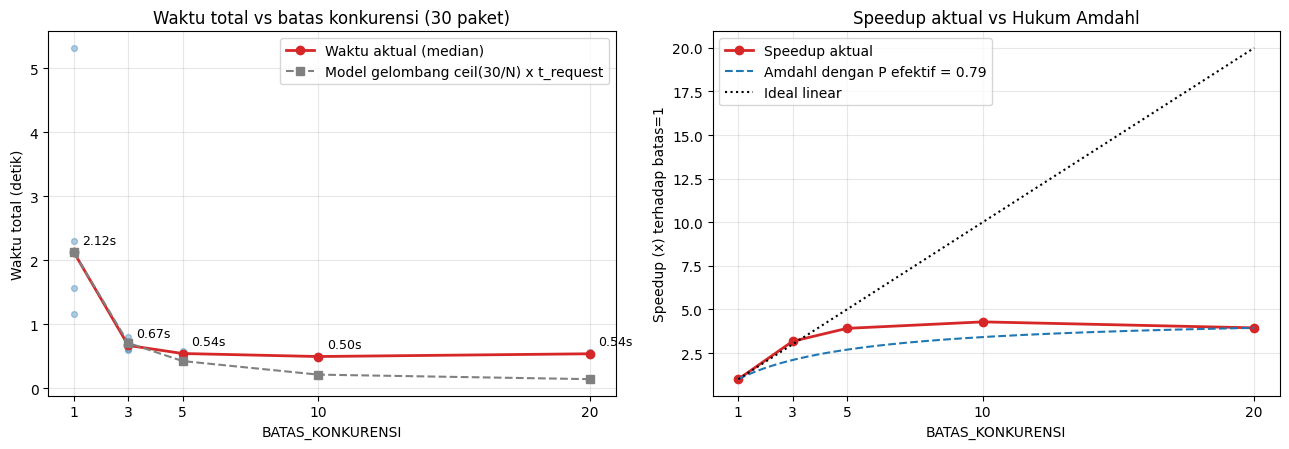

In [5]:
# --- Plot: waktu vs batas konkurensi, speedup vs Amdahl ---
N_PAKET = len(daftar_paket_banyak)
T1 = waktu_med[1]
t_req = T1 / N_PAKET                                    # estimasi waktu 1 request (batas=1)
speedup1 = {b: T1 / waktu_med[b] for b in BATAS_LIST}
ideal = {b: math.ceil(N_PAKET / b) * t_req for b in BATAS_LIST}   # model gelombang

# Estimasi fraksi paralel efektif P dari titik batas terbesar: S = 1/((1-P)+P/N)
Nmax = max(BATAS_LIST); Smax = speedup1[Nmax]
P_eff = max(0.0, min(1.0, (1/Smax - 1) / (1/Nmax - 1)))
amdahl = lambda P, n: 1 / ((1 - P) + P / n)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))

# (kiri) waktu vs batas
for b in BATAS_LIST:
    ax[0].scatter([b]*ULANG, mentah[b], color='tab:blue', alpha=0.35, s=18)
ax[0].plot(BATAS_LIST, [waktu_med[b] for b in BATAS_LIST], 'o-', lw=2, color='tab:red', label='Waktu aktual (median)')
ax[0].plot(BATAS_LIST, [ideal[b] for b in BATAS_LIST], 's--', color='gray', label='Model gelombang ceil(30/N) x t_request')
for b in BATAS_LIST:
    ax[0].annotate(f"{waktu_med[b]:.2f}s", (b, waktu_med[b]), textcoords='offset points', xytext=(6, 6), fontsize=9)
ax[0].set_xlabel('BATAS_KONKURENSI'); ax[0].set_ylabel('Waktu total (detik)')
ax[0].set_title(f'Waktu total vs batas konkurensi ({N_PAKET} paket)')
ax[0].set_xticks(BATAS_LIST); ax[0].grid(alpha=0.3); ax[0].legend()

# (kanan) speedup vs Amdahl
Ns = np.linspace(1, Nmax, 200)
ax[1].plot(BATAS_LIST, [speedup1[b] for b in BATAS_LIST], 'o-', lw=2, color='tab:red', label='Speedup aktual')
ax[1].plot(Ns, amdahl(P_eff, Ns), '--', color='tab:blue', label=f'Amdahl dengan P efektif = {P_eff:.2f}')
ax[1].plot(Ns, Ns, ':', color='black', label='Ideal linear')
ax[1].set_xlabel('BATAS_KONKURENSI'); ax[1].set_ylabel('Speedup (x) terhadap batas=1')
ax[1].set_title('Speedup aktual vs Hukum Amdahl')
ax[1].set_xticks(BATAS_LIST); ax[1].grid(alpha=0.3); ax[1].legend()
plt.tight_layout(); plt.show()

In [6]:
# --- Ringkasan otomatis (menyesuaikan hasil di mesin/jaringan kamu) ---
AMBANG = 0.10     # "manfaat sangat kecil" := penambahan batas memangkas waktu < 10%
print(f"{'BATAS':>5} | {'gelombang':>9} | {'median':>8} | {'speedup':>8} | {'efisiensi':>9} | {'hemat vs batas sebelumnya':>26}")
prev = None
for b in BATAS_LIST:
    hemat = "-" if prev is None else f"{(waktu_med[prev]-waktu_med[b])/waktu_med[prev]*100:>5.1f}%"
    print(f"{b:>5} | {math.ceil(N_PAKET/b):>9} | {waktu_med[b]:>7.3f}s | {speedup1[b]:>7.2f}x | {speedup1[b]/b*100:>8.0f}% | {hemat:>26}")
    prev = b

titik = None
for a, b in zip(BATAS_LIST, BATAS_LIST[1:]):
    if (waktu_med[a] - waktu_med[b]) / waktu_med[a] < AMBANG:
        titik = a; break
print()
if titik is None:
    print(f"-> Setiap kenaikan batas sampai {BATAS_LIST[-1]} masih memangkas waktu >= {AMBANG*100:.0f}% di percobaan ini.")
else:
    print(f"-> Titik diminishing returns: batas = {titik}. Menaikkan batas dari {titik} ke batas berikutnya "
          f"memangkas waktu < {AMBANG*100:.0f}%.")
print(f"-> Estimasi P efektif (dari batas={Nmax}): {P_eff:.2f}  ->  batas atas speedup Amdahl = "
      f"{(1/(1-P_eff) if P_eff < 1 else float('inf')):.1f}x; speedup aktual tertinggi = {max(speedup1.values()):.2f}x")

BATAS | gelombang |   median |  speedup | efisiensi |  hemat vs batas sebelumnya
    1 |        30 |   2.124s |    1.00x |      100% |                          -
    3 |        10 |   0.669s |    3.17x |      106% |                      68.5%
    5 |         6 |   0.543s |    3.91x |       78% |                      18.9%
   10 |         3 |   0.496s |    4.29x |       43% |                       8.7%
   20 |         2 |   0.539s |    3.94x |       20% |                      -8.7%

-> Titik diminishing returns: batas = 5. Menaikkan batas dari 5 ke batas berikutnya memangkas waktu < 10%.
-> Estimasi P efektif (dari batas=20): 0.79  ->  batas atas speedup Amdahl = 4.7x; speedup aktual tertinggi = 4.29x


### Penjelasan Soal 1

**Hasil:** waktu total turun tajam ketika batas dinaikkan dari 1 ke batas kecil lainnya, tetapi kurva cepat mendatar. Titik di mana tambahan batas hanya menghemat sedikit (< 10% menurut definisi saya) ditampilkan otomatis di sel ringkasan; angka tepatnya bergantung pada jaringan saat notebook dijalankan.

**Mengapa penambahan batas lama-kelamaan tidak banyak membantu (kaitan dengan Hukum Amdahl dan *diminishing returns*)?**

Pada soal ini "jumlah prosesor" $N$ pada rumus Amdahl dianalogikan dengan `BATAS_KONKURENSI`. Karena yang ditunggu adalah jaringan, bukan CPU, bagian yang bisa dioverlapkan (menunggu respons) memang besar, tetapi tidak 100%:

1. **Bagian serial ($1-P$) tidak ikut mengecil.** Event loop hanya satu thread, sehingga *parsing* JSON, pembuatan objek, dan penjadwalan coroutine tetap dikerjakan satu per satu. Tiap koneksi baru juga memerlukan *handshake* TCP/TLS yang dikerjakan di loop yang sama. Semakin besar $N$, semakin dominan porsi serial ini terhadap waktu total, persis seperti $S \to 1/(1-P)$ pada Amdahl.
2. **Efek gelombang (granularitas).** Dengan 30 tugas, batas 10 menghasilkan 3 gelombang, batas 20 hanya 2 gelombang, dan batas ≥ 30 satu gelombang. Setelah gelombang tinggal sedikit, kenaikan batas hanya mengurangi jumlah gelombang sedikit demi sedikit, dan batas di atas 30 tidak berguna sama sekali (tidak ada tugas yang bisa dijalankan tambahan).
3. **Batas di luar kendali program.** Latensi server PyPI/CDN, bandwidth, dan *rate limit* membuat request tidak semuanya makin cepat ketika dikirim serentak; selain itu satu request yang lambat menentukan lamanya satu gelombang.
4. **Overhead konkurensi ikut naik.** Lebih banyak koneksi berarti lebih banyak *handshake* dan lebih banyak objek yang harus dikelola loop, sehingga keuntungan marjinal makin kecil.

**Catatan kualitas data:** latensi jaringan sungguhan tidak konstan. Jika pada tabel muncul efisiensi di atas 100% atau batas yang lebih besar justru tampak lebih lambat, itu hampir selalu tanda satu atau dua ulangan terkena lonjakan latensi (terlihat pada kolom ulangan dan titik biru di grafik kiri), bukan tanda bahwa konkurensi "lebih dari ideal". Itulah alasan memakai median dan 5 ulangan, bukan satu kali ukur.

**Kesimpulan:** kurva aktual mengikuti pola *diminishing returns* Amdahl: keuntungan terbesar didapat pada beberapa penambahan batas pertama, lalu mendatar mendekati batas atas $1/(1-P)$. Dalam praktik, batas yang "cukup" ditentukan oleh titik tekuk ini, bukan oleh batas setinggi mungkin. Batas yang terlalu tinggi justru berisiko membebani server tujuan dan terkena *rate limit* tanpa menambah kecepatan yang berarti.

### SOAL NOMOR 2

Soal Nomor 2:
Deteksi Blocking Call: Buat 3 coroutine berbeda: satu memakai asyncio.sleep(), satu memakai time.sleep(), dan satu lagi memakai operasi CPU-bound murni (misalnya hitung faktorial dari angka besar dalam loop, tanpa await sama sekali). Jalankan ketiganya dengan asyncio.gather() bersama satu coroutine asyncio.sleep() lain sebagai "pengukur". Amati dan jelaskan coroutine mana saja yang mengganggu jalannya coroutine pengukur, dan mengapa.

**Rancangan eksperimen**

- **Tiga coroutine uji**, masing-masing "bekerja" sekitar 1 detik:
  - `korut_async_sleep`: `await asyncio.sleep(1.0)` (non-blocking, menyerahkan giliran).
  - `korut_time_sleep`: `time.sleep(1.0)` (blocking, **tanpa** `await`).
  - `korut_cpu`: loop perkalian faktorial angka besar, **tanpa `await` sama sekali**. Angka `n` dikalibrasi otomatis agar durasinya ≈ 1 detik di mesin ini.
- **Coroutine pengukur:** mengulang `await asyncio.sleep(0.1)` sebanyak 20 kali dan mencatat berapa lama tiap tidur *sebenarnya* berlangsung. Jika event loop bebas, tiap tidur ≈ 0,1 detik. Selisih terhadap 0,1 detik disebut **lag**. Lag besar berarti ada yang memblokir loop.
- **Skenario:** (S0) pengukur + `asyncio.sleep` sebagai kontrol, (S1) pengukur + `time.sleep`, (S2) pengukur + CPU-bound, dan (S3) **semuanya sekaligus** lewat satu `asyncio.gather()` seperti yang diminta soal. S1 dan S2 dipisah supaya terlihat jelas pelaku masing-masing.

In [7]:
# --- Kalibrasi beban CPU-bound agar ~1 detik ---
def faktorial_loop(n):
    """CPU-bound murni: perkalian bilangan besar dalam loop, tidak ada await."""
    hasil = 1
    for i in range(2, n + 1):
        hasil *= i
    return hasil

DURASI = 1.0
n0 = 20_000
t0 = time.perf_counter(); faktorial_loop(n0); dt0 = time.perf_counter() - t0
FAKTORIAL_N = max(1000, int(n0 * math.sqrt(DURASI / dt0)))     # biaya ~ kuadratik terhadap n
t0 = time.perf_counter(); faktorial_loop(FAKTORIAL_N); dt = time.perf_counter() - t0
print(f"faktorial({n0:,})            : {dt0:.3f} detik")
print(f"faktorial({FAKTORIAL_N:,}) : {dt:.3f} detik   <- dipakai sebagai beban CPU-bound (target ~{DURASI} detik)")

faktorial(20,000)            : 0.080 detik
faktorial(70,501) : 1.219 detik   <- dipakai sebagai beban CPU-bound (target ~1.0 detik)


In [8]:
# --- Tiga coroutine uji + coroutine pengukur ---
async def korut_async_sleep(rec, t0, durasi):
    mulai = time.perf_counter() - t0
    await asyncio.sleep(durasi)                       # NON-blocking
    rec['asyncio.sleep'] = (mulai, time.perf_counter() - t0)

async def korut_time_sleep(rec, t0, durasi):
    mulai = time.perf_counter() - t0
    time.sleep(durasi)                                # BLOCKING: tidak ada await
    rec['time.sleep'] = (mulai, time.perf_counter() - t0)

async def korut_cpu(rec, t0, n):
    mulai = time.perf_counter() - t0
    faktorial_loop(n)                                 # CPU-bound murni: tidak ada await
    rec['CPU-bound'] = (mulai, time.perf_counter() - t0)

async def pengukur(rec, t0, interval=0.1, jumlah=20):
    """Tidur 0.1 detik berulang-ulang; catat lag = (lama tidur sebenarnya) - 0.1."""
    mulai = time.perf_counter() - t0
    ticks = []
    for _ in range(jumlah):
        a = time.perf_counter()
        await asyncio.sleep(interval)
        b = time.perf_counter()
        ticks.append((b - t0, (b - a) - interval))
    rec['pengukur'] = (mulai, ticks[-1][0])
    rec['ticks'] = ticks

SKENARIO = {
    "S0 kontrol : pengukur + asyncio.sleep":      lambda r, t: [korut_async_sleep(r, t, DURASI)],
    "S1 pengukur + time.sleep":                    lambda r, t: [korut_time_sleep(r, t, DURASI)],
    "S2 pengukur + CPU-bound":                     lambda r, t: [korut_cpu(r, t, FAKTORIAL_N)],
    "S3 SEMUA (3 uji + pengukur) via gather":      lambda r, t: [korut_async_sleep(r, t, DURASI),
                                                                 korut_time_sleep(r, t, DURASI),
                                                                 korut_cpu(r, t, FAKTORIAL_N)],
}

async def jalankan_skenario(nama):
    rec = {}
    t0 = time.perf_counter()
    await asyncio.gather(pengukur(rec, t0), *SKENARIO[nama](rec, t0))   # pengukur ditulis pertama
    total = time.perf_counter() - t0
    lags = [l for _, l in rec['ticks']]
    return {"nama": nama, "total": total, "lag_max": max(lags), "lag_rata": sum(lags)/len(lags), "rec": rec}

hasil_skenario = {}
for nama in SKENARIO:
    hasil_skenario[nama] = await jalankan_skenario(nama)

TOLERANSI = 0.05      # lag > 50 ms dianggap "terganggu"
print(f"Nominal pengukur tanpa gangguan = 20 x 0.1 = 2.00 detik; toleransi lag = {TOLERANSI*1000:.0f} ms\n")
print(f"{'skenario':<42} | {'total':>7} | {'lag maks':>9} | {'lag rata2':>9} | status pengukur")
for nama, r in hasil_skenario.items():
    status = "TERGANGGU" if r['lag_max'] > TOLERANSI else "normal"
    print(f"{nama:<42} | {r['total']:>6.2f}s | {r['lag_max']*1000:>7.0f}ms | {r['lag_rata']*1000:>7.0f}ms | {status}")

Nominal pengukur tanpa gangguan = 20 x 0.1 = 2.00 detik; toleransi lag = 50 ms

skenario                                   |   total |  lag maks | lag rata2 | status pengukur
S0 kontrol : pengukur + asyncio.sleep      |   2.01s |       0ms |       0ms | normal
S1 pengukur + time.sleep                   |   2.91s |     900ms |      45ms | TERGANGGU
S2 pengukur + CPU-bound                    |   3.12s |    1114ms |      56ms | TERGANGGU
S3 SEMUA (3 uji + pengukur) via gather     |   4.16s |    2150ms |     108ms | TERGANGGU


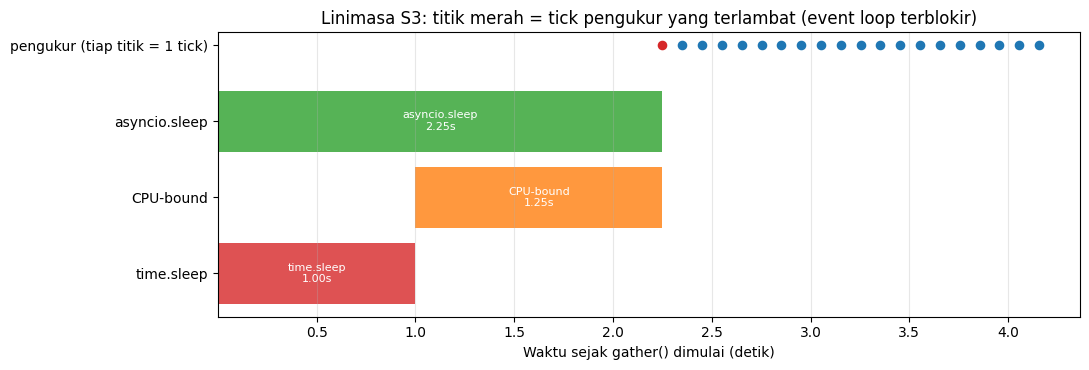

Tick pengukur pertama-tiga (waktu muncul, lag):
  t =  2.25s   lag =   2150 ms
  t =  2.35s   lag =      0 ms
  t =  2.45s   lag =      0 ms
Selesainya coroutine asyncio.sleep(1.0) pada S3 (nominal 1.00s): 2.25s  -> ikut terlambat karena loop terblokir


In [9]:
# --- Visualisasi linimasa skenario S3 (semuanya bersamaan) ---
r3 = hasil_skenario["S3 SEMUA (3 uji + pengukur) via gather"]["rec"]
fig, ax = plt.subplots(figsize=(11, 3.8))
baris = ['time.sleep', 'CPU-bound', 'asyncio.sleep']
warna = {'time.sleep': 'tab:red', 'CPU-bound': 'tab:orange', 'asyncio.sleep': 'tab:green'}
for i, nm in enumerate(baris):
    m, s = r3[nm]
    ax.barh(i, s - m, left=m, color=warna[nm], alpha=0.8)
    ax.text(m + (s - m)/2, i, f"{nm}\n{s-m:.2f}s", ha='center', va='center', fontsize=8, color='white')
y_peng = len(baris)
for t_tick, lag in r3['ticks']:
    ax.scatter(t_tick, y_peng, color='tab:red' if lag > TOLERANSI else 'tab:blue', s=35, zorder=3)
ax.set_yticks(range(len(baris) + 1)); ax.set_yticklabels(baris + ['pengukur (tiap titik = 1 tick)'])
ax.set_xlabel('Waktu sejak gather() dimulai (detik)')
ax.set_title('Linimasa S3: titik merah = tick pengukur yang terlambat (event loop terblokir)')
ax.grid(axis='x', alpha=0.3); plt.tight_layout(); plt.show()

print("Tick pengukur pertama-tiga (waktu muncul, lag):")
for t_tick, lag in r3['ticks'][:3]:
    print(f"  t = {t_tick:5.2f}s   lag = {lag*1000:6.0f} ms")
print("Selesainya coroutine asyncio.sleep(1.0) pada S3 (nominal 1.00s):",
      f"{r3['asyncio.sleep'][1]:.2f}s  -> ikut terlambat karena loop terblokir")

**Bonus: deteksi otomatis lewat *debug mode* asyncio.** Event loop punya mode debug yang mencatat setiap langkah coroutine yang berjalan lebih lama dari `slow_callback_duration`. Dengan ini pelaku pemblokiran bisa diketahui tanpa menebak dari pola waktu.

In [10]:
loop = asyncio.get_running_loop()
catatan_lambat = []

class PencatatLambat(logging.Handler):
    def emit(self, record):
        catatan_lambat.append(record.getMessage())

handler = PencatatLambat()
logger_asyncio = logging.getLogger("asyncio")
logger_asyncio.addHandler(handler)
loop.set_debug(True)
loop.slow_callback_duration = 0.1            # laporkan langkah yang menahan loop > 100 ms
try:
    await jalankan_skenario("S3 SEMUA (3 uji + pengukur) via gather")
finally:
    loop.set_debug(False)
    logger_asyncio.removeHandler(handler)

laporan = [m for m in catatan_lambat if "took" in m]
print(f"Langkah yang terdeteksi memblokir event loop: {len(laporan)}\n")
import re
for m in laporan:
    nama_korut = re.search(r"coro=<(\w+)", m)
    durasi_m = re.search(r"took ([0-9.]+) seconds", m)
    print(f" * {nama_korut.group(1) if nama_korut else '?':<18} menahan event loop selama {durasi_m.group(1) if durasi_m else '?'} detik")

Langkah yang terdeteksi memblokir event loop: 2

 * korut_time_sleep   menahan event loop selama 1.000 detik
 * korut_cpu          menahan event loop selama 1.157 detik


### Penjelasan Soal 2

**Coroutine mana yang mengganggu pengukur?**

| Coroutine | Mengganggu pengukur? | Alasan |
|---|---|---|
| `await asyncio.sleep()` | **Tidak** | Titik `await` menyerahkan kendali ke event loop; selama menunggu, loop bebas menjalankan pengukur dan coroutine lain. Skenario kontrol (S0) menunjukkan lag ≈ 0. |
| `time.sleep()` | **Ya** | Fungsi ini menidurkan **seluruh thread**, dan karena semua coroutine berbagi satu thread, event loop ikut tertidur. Pengukur tidak bisa bangun walaupun timer 0,1 detiknya sudah lewat. |
| Loop CPU-bound (faktorial) | **Ya** | Tidak ada `await` di dalamnya, sehingga coroutine ini tidak pernah menyerahkan giliran. Event loop sibuk menghitung, bukan tidur, tetapi dampaknya sama: tidak ada coroutine lain yang berjalan sampai loop selesai. |

**Mengapa?** Asyncio memakai *cooperative multitasking*: pergantian giliran hanya terjadi di titik `await`. Tidak ada penjadwal OS yang memaksa coroutine berhenti (tidak ada *preemption*). Maka satu coroutine yang "tidak kooperatif" menahan semua coroutine lain, termasuk yang tampak tidak ada hubungannya.

**Pengamatan pada S3 (gabungan):** karena `gather()` menjalankan langkah pertama tiap coroutine secara berurutan, `time.sleep` dan loop CPU-bound dieksekusi **satu setelah yang lain** tanpa jeda. Akibatnya lag pengukur kira-kira sama dengan **jumlah** durasi keduanya, bukan yang terbesar. Coroutine `asyncio.sleep(1.0)` yang sebenarnya tidak bersalah pun ikut selesai terlambat, karena timernya baru bisa diproses setelah loop bebas lagi.

**Perbedaan halus keduanya:** `time.sleep` adalah blocking pada I/O (menunggu), sehingga bisa diganti satu-satu dengan `await asyncio.sleep`. Loop CPU-bound tidak bisa "diperbaiki" dengan mengganti satu baris, karena memang pekerjaannya menghitung. Solusinya memindahkan pekerjaan itu keluar dari event loop: `await loop.run_in_executor(...)` dengan `ProcessPoolExecutor` (CPU-bound; lihat Pertemuan 3) atau `asyncio.to_thread()` untuk fungsi blocking I/O.

**Cara mendeteksi di dunia nyata:** (1) pantau lag coroutine "pengukur" seperti di sini, (2) aktifkan debug mode seperti pada sel bonus, yang langsung menunjuk coroutine dan lamanya, dan (3) pakai `await asyncio.sleep(0)` secara berkala di dalam loop panjang bila terpaksa, agar loop sempat berpindah giliran.

### SOAL NOMOR 3

Soal Nomor 3:
Producer-Multi-Consumer dengan Prioritas: Modifikasi contoh asyncio.Queue pada bagian 6.4 agar setiap item memiliki "prioritas" (angka 1–3), dan consumer harus memproses item berprioritas tinggi (angka lebih kecil) lebih dulu. (Hint: cari tahu tentang asyncio.PriorityQueue.)

**Rancangan eksperimen**

Struktur kode sama dengan bagian 6.4 (satu producer, 3 consumer, penutupan dengan sentinel `None` per consumer). Perubahannya:

| Aspek | Bagian 6.4 (`asyncio.Queue`) | Versi prioritas (`asyncio.PriorityQueue`) |
|---|---|---|
| Antrean | `asyncio.Queue(maxsize=5)` | `asyncio.PriorityQueue()` |
| Isi antrean | `"item-3"` | tuple `(prioritas, nomor_urut, nama_item, ...)` |
| Urutan keluar | FIFO | prioritas terkecil dulu; seri dipecah oleh `nomor_urut` |

Poin penting yang membuat solusi ini benar:

- **Tuple dibandingkan elemen demi elemen.** `PriorityQueue` mengurutkan item dengan `<`. `nomor_urut` (dari `itertools.count`) menjamin dua item berprioritas sama tidak pernah membandingkan elemen berikutnya, sekaligus menjaga urutan kedatangan di antara prioritas sama.
- **Sentinel diberi prioritas 99** (paling "tidak penting"). Jika sentinel berprioritas 1, ia keluar lebih dulu dan consumer berhenti sebelum item biasa habis.
- **Prioritas hanya berpengaruh jika ada antrean.** Jika consumer lebih cepat daripada producer, antrean selalu kosong dan setiap item langsung diambil, apa pun prioritasnya. Maka producer dibuat lebih cepat (0,02 detik per item) daripada consumer (0,15 detik per item) agar backlog terbentuk. Antrean juga tidak dibatasi `maxsize`, karena batas kecil membuat producer menunggu dan hanya item di buffer yang bisa diurutkan.
- **Dibandingkan dengan FIFO:** item dan seed yang sama dijalankan juga pada `asyncio.Queue` biasa sebagai kontrol, supaya efek prioritas terlihat nyata, bukan sekadar klaim.

In [11]:
JUMLAH_ITEM_P = 15
JUMLAH_CONSUMER_P = 3
WAKTU_PRODUKSI = 0.02          # producer cepat
WAKTU_PROSES = 0.15            # consumer lambat -> terbentuk backlog
PRIO_SENTINEL = 99

async def producer_p(queue, seed, log):
    rng = random.Random(seed)
    nomor = itertools.count()
    for i in range(JUMLAH_ITEM_P):
        prio = rng.randint(1, 3)
        await asyncio.sleep(WAKTU_PRODUKSI)
        seq = next(nomor)
        log['put'][seq] = (time.perf_counter(), prio, f"item-{i}")
        await queue.put((prio, seq, f"item-{i}"))
    for _ in range(JUMLAH_CONSUMER_P):                       # 1 sentinel per consumer
        await queue.put((PRIO_SENTINEL, next(nomor), None))

async def consumer_p(queue, nama, log):
    while True:
        prio, seq, item = await queue.get()
        if item is None:
            queue.task_done()
            break
        log['get'].append((time.perf_counter(), nama, prio, seq, item))
        await asyncio.sleep(WAKTU_PROSES)
        queue.task_done()

async def jalankan_pipeline_p(QueueCls, seed=7):
    log = {'put': {}, 'get': []}
    queue = QueueCls()
    t0 = time.perf_counter()
    await asyncio.gather(
        producer_p(queue, seed, log),
        *[consumer_p(queue, f"Consumer-{i}", log) for i in range(JUMLAH_CONSUMER_P)],
    )
    return log, time.perf_counter() - t0

log_fifo, t_fifo = await jalankan_pipeline_p(asyncio.Queue)
log_prio, t_prio = await jalankan_pipeline_p(asyncio.PriorityQueue)

def cetak_urutan(judul, log):
    print(judul)
    print(f"{'ke':>3} | {'consumer':<10} | {'prioritas':>9} | {'item':<8} | menunggu di antrean")
    for k, (t_get, cons, prio, seq, item) in enumerate(log['get'], 1):
        tunggu = (t_get - log['put'][seq][0]) * 1000
        print(f"{k:>3} | {cons:<10} | {prio:>9} | {item:<8} | {tunggu:>8.0f} ms")
    print()

cetak_urutan("=== FIFO: asyncio.Queue (kontrol) ===", log_fifo)
cetak_urutan("=== PRIORITAS: asyncio.PriorityQueue ===", log_prio)
print(f"Waktu total  FIFO: {t_fifo:.2f}s   Prioritas: {t_prio:.2f}s  (sama: jumlah kerja identik, hanya urutannya yang berbeda)")

=== FIFO: asyncio.Queue (kontrol) ===
 ke | consumer   | prioritas | item     | menunggu di antrean
  1 | Consumer-0 |         2 | item-0   |        0 ms
  2 | Consumer-1 |         1 | item-1   |        0 ms
  3 | Consumer-2 |         2 | item-2   |        0 ms
  4 | Consumer-0 |         3 | item-3   |       91 ms
  5 | Consumer-1 |         1 | item-4   |       89 ms
  6 | Consumer-2 |         1 | item-5   |       90 ms
  7 | Consumer-0 |         3 | item-6   |      182 ms
  8 | Consumer-1 |         1 | item-7   |      179 ms
  9 | Consumer-2 |         2 | item-8   |      180 ms
 10 | Consumer-0 |         3 | item-9   |      272 ms
 11 | Consumer-1 |         1 | item-10  |      268 ms
 12 | Consumer-2 |         3 | item-11  |      269 ms
 13 | Consumer-0 |         1 | item-12  |      361 ms
 14 | Consumer-1 |         1 | item-13  |      358 ms
 15 | Consumer-2 |         1 | item-14  |      359 ms

=== PRIORITAS: asyncio.PriorityQueue ===
 ke | consumer   | prioritas | item     | menung

Inversi prioritas  FIFO: 20   PriorityQueue: 0   (PriorityQueue harus 0)
Jumlah item per prioritas: {1: 8, 2: 3, 3: 4}



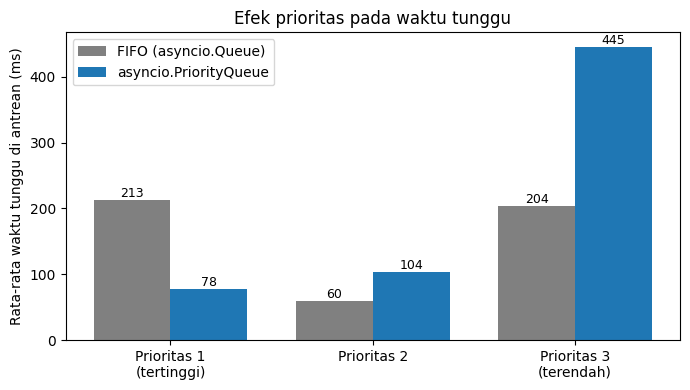

In [12]:
# --- Bukti terukur: hitung "inversi prioritas" + rata-rata waktu tunggu per prioritas ---
def inversi(log, eps=1e-4):
    """Inversi = item B (kurang penting) diambil SEBELUM item A (lebih penting) padahal A sudah ada di antrean."""
    get = {seq: (t, prio) for t, _, prio, seq, _ in log['get']}
    jumlah = 0
    for seq_b, (t_get_b, prio_b) in get.items():
        for seq_a, (t_put_a, prio_a, _) in log['put'].items():
            if prio_a < prio_b and t_put_a < t_get_b - eps and get[seq_a][0] > t_get_b + eps:
                jumlah += 1
    return jumlah

def tunggu_per_prio(log):
    hasil = {1: [], 2: [], 3: []}
    for t_get, _, prio, seq, _ in log['get']:
        hasil[prio].append((t_get - log['put'][seq][0]) * 1000)
    return {p: (sum(v)/len(v) if v else float('nan')) for p, v in hasil.items()}, {p: len(v) for p, v in hasil.items()}

inv_fifo, inv_prio = inversi(log_fifo), inversi(log_prio)
tw_fifo, cnt = tunggu_per_prio(log_fifo)
tw_prio, _ = tunggu_per_prio(log_prio)
print(f"Inversi prioritas  FIFO: {inv_fifo}   PriorityQueue: {inv_prio}   (PriorityQueue harus 0)")
assert inv_prio == 0, "PriorityQueue seharusnya tidak punya inversi prioritas"
print(f"Jumlah item per prioritas: {cnt}\n")

x = np.arange(3); lebar = 0.38
fig, ax = plt.subplots(figsize=(7, 4))
b1 = ax.bar(x - lebar/2, [tw_fifo[p] for p in (1, 2, 3)], lebar, label='FIFO (asyncio.Queue)', color='gray')
b2 = ax.bar(x + lebar/2, [tw_prio[p] for p in (1, 2, 3)], lebar, label='asyncio.PriorityQueue', color='tab:blue')
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"{b.get_height():.0f}", ha='center', va='bottom', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(['Prioritas 1\n(tertinggi)', 'Prioritas 2', 'Prioritas 3\n(terendah)'])
ax.set_ylabel('Rata-rata waktu tunggu di antrean (ms)'); ax.set_title('Efek prioritas pada waktu tunggu')
ax.legend(); plt.tight_layout(); plt.show()

### Penjelasan Soal 3

**Perubahan yang diperlukan sangat kecil**: `asyncio.Queue` diganti `asyncio.PriorityQueue`, dan item dibungkus tuple `(prioritas, nomor_urut, isi)`. Fungsi `producer` dan `consumer` tetap memakai `await queue.put()` dan `await queue.get()` yang sama persis.

**Hasil:** pada tabel FIFO, item keluar sesuai urutan kedatangan sehingga prioritas tercampur (ada inversi). Pada `PriorityQueue`, setiap kali consumer bebas ia mengambil item berprioritas terkecil di antara yang sedang menunggu, sehingga jumlah inversi **nol**. Grafik menunjukkan konsekuensinya: item prioritas 1 menunggu paling singkat, dan "biayanya" ditanggung item prioritas 3 yang menunggu paling lama. Waktu total tidak berubah, karena jumlah pekerjaan sama; yang berubah hanya *siapa* yang dilayani lebih dulu.

**Catatan penting:**

- Tiga item pertama tetap diambil langsung walaupun prioritasnya tidak 1, karena saat itu antrean masih kosong dan consumer sedang menganggur. Prioritas hanya mengatur urutan di antara item yang **sedang menunggu bersamaan**.
- Sentinel berprioritas 99 memastikan semua item nyata habis diproses sebelum consumer berhenti.
- **Risiko *starvation*:** jika item prioritas tinggi terus berdatangan, item prioritas 3 bisa menunggu tanpa batas. Pada sistem nyata biasanya ditambahkan *aging* (prioritas naik seiring lamanya menunggu).
- `PriorityQueue` tidak punya jaminan FIFO di antara prioritas sama kecuali kita menambahkan `nomor_urut` seperti di sini; tanpa itu Python akan membandingkan elemen berikutnya di tuple (dan bisa error bila tidak bisa dibandingkan).

### SOAL NOMOR 4

Soal Nomor 4:
Refleksi singkat (maks. 150 kata): Bandingkan pengalaman kalian menulis kode paralel dengan threading (Pertemuan 2), multiprocessing (Pertemuan 3), dan asyncio (pertemuan ini) untuk kasus I/O-bound. Mana yang menurut kalian paling mudah dipahami dan mengapa? Berikan alasan berbasis pengalaman coding kalian, bukan hanya teori.

Sebagai dasar refleksi, berikut benchmark kecil yang sama untuk ketiganya: **20 tugas I/O-bound**, masing-masing "menunggu" 0,2 detik (simulasi menunggu respons jaringan). Satu unit konkurensi per tugas: 20 thread, 20 proses, atau 20 coroutine. Kode sekuensial membutuhkan sekitar $20 \times 0{,}2 = 4$ detik.

In [13]:
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor
import tugas4_helpers as h4

JUMLAH_TUGAS, DURASI_IO = 20, 0.2
beban = [DURASI_IO] * JUMLAH_TUGAS
T_SEKUENSIAL = JUMLAH_TUGAS * DURASI_IO

# threading (Pertemuan 2)
t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=JUMLAH_TUGAS) as ex:
    r_thr = list(ex.map(h4.tugas_io, beban))
t_thr = time.perf_counter() - t0

# multiprocessing (Pertemuan 3)
t0 = time.perf_counter()
with ProcessPoolExecutor(max_workers=JUMLAH_TUGAS) as ex:
    r_proc = list(ex.map(h4.tugas_io, beban))
t_proc = time.perf_counter() - t0

# asyncio (pertemuan ini)
async def tugas_io_async(durasi):
    await asyncio.sleep(durasi)
    return durasi

t0 = time.perf_counter()
r_async = await asyncio.gather(*[tugas_io_async(d) for d in beban])
t_async = time.perf_counter() - t0

assert r_thr == r_proc == r_async == beban
print(f"Sekuensial (teoretis)      : {T_SEKUENSIAL:.2f} detik")
print(f"threading   ({JUMLAH_TUGAS} thread)     : {t_thr:.2f} detik   speedup {T_SEKUENSIAL/t_thr:.1f}x")
print(f"multiprocessing ({JUMLAH_TUGAS} proses) : {t_proc:.2f} detik   speedup {T_SEKUENSIAL/t_proc:.1f}x")
print(f"asyncio     ({JUMLAH_TUGAS} coroutine)  : {t_async:.2f} detik   speedup {T_SEKUENSIAL/t_async:.1f}x")
print(f"\nWaktu ideal = {DURASI_IO:.2f} detik (semua tugas menunggu bersamaan). Selisih di atas 0,2 detik adalah overhead membuat 20 thread/proses/coroutine.")

Sekuensial (teoretis)      : 4.00 detik
threading   (20 thread)     : 0.20 detik   speedup 19.8x
multiprocessing (20 proses) : 0.32 detik   speedup 12.5x
asyncio     (20 coroutine)  : 0.20 detik   speedup 19.9x

Waktu ideal = 0.20 detik (semua tugas menunggu bersamaan). Selisih di atas 0,2 detik adalah overhead membuat 20 thread/proses/coroutine.


### Refleksi

Untuk kasus I/O-bound, asyncio paling mudah saya pahami. Pada threading, saya harus memikirkan Lock dan race condition karena OS bisa menukar thread kapan saja. Pada multiprocessing, hambatannya teknis: fungsi harus bisa di-pickle sehingga di Windows saya menulis helper lewat `%%writefile`, hasil harus dikirim lewat Queue, dan join sebelum get bisa deadlock. Di asyncio alurnya terbaca seperti kode biasa: giliran berpindah hanya di `await`, jadi saya tahu persis di mana program berhenti. Tanpa file helper, tanpa Lock, dan 30 request selesai dalam satu `gather()`.

Namun asyncio punya jebakan sendiri: satu `time.sleep` atau loop CPU-bound membekukan semua coroutine tanpa pesan error, dan baru terlihat dari waktu yang membengkak (soal 2). Seluruh rantai juga harus async (`aiohttp`, bukan `requests`). Tetap saja, bagi saya asyncio paling mudah dipahami dan diprediksi.